# Robust covariance estimation and Mahalanobis distances: scikit-learn vs Moxie

**Reference example:** `../scikit-learn/examples/covariance/plot_mahalanobis_distances.py`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/covariance/plot_mahalanobis_distances.html))
at scikit-learn `4358542a1bd39af2e7e1cbace8b9fed067473c5b`.

**Scenario:** 125 two-dimensional Gaussian samples (`np.random.seed(7)`), the last 25 replaced by outliers from a
different covariance. `MinCovDet` and `EmpiricalCovariance` are fitted; their `mahalanobis` distances are evaluated on
a 100x100 grid (contours) and on the training data shifted by each estimator's location (box plots).

**Beyond the gallery:** MinCovDet's `raw_location_`, `raw_covariance_`, `raw_support_`, `support_`, `dist_`,
`precision_`, `correct_covariance`, `reweight_covariance`, `score` and `error_norm`; the `fast_mcd` function;
`EllipticEnvelope(contamination=0.2)` with `fit_predict`, `predict`, `decision_function`, `score_samples`, `offset_` and
weighted `score`; `set_params(support_fraction=0.9)` + refit; and Float32 `MinCovDet`.

**Adaptations:**
- The official example calls `MinCovDet()` with `random_state=None`, so its FastMCD subsets depend on NumPy's global
  RNG state. Both sides here use `random_state=0`: Moxie's robust child ports NumPy's legacy `RandomState` (MT19937)
  draw order, so an integer seed reproduces sklearn's subsets (`families/covariance/algorithms/robust/docs/api.md`).
  With `random_state=None` Moxie uses an entropy-seeded native state instead of NumPy's global one.
- The seeded data is generated by the official code in Python and shared.
- Learned attributes are accessor methods; labels are Int64 arrays; errors are Mojo `Error`s with sklearn
  exception-name prefixes.

**Determinism:** deterministic with the fixed seed. Supports and labels are compared exactly; estimates and distances
numerically.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("covariance/plot_mahalanobis_distances")

## 1. scikit-learn (Python reference)

The official example code (small figures; `random_state=0`).

Estimated covariance matrix:
MCD (Robust):
[[ 3.60075119 -0.07640781]
 [-0.07640781  1.51855963]]
MLE:
[[ 3.23773583 -0.24640578]
 [-0.24640578  7.51963999]]


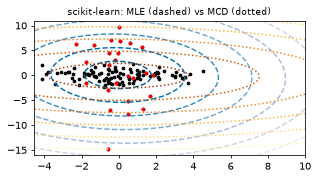

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.covariance import EmpiricalCovariance, MinCovDet

np.random.seed(7)
n_samples = 125
n_outliers = 25
n_features = 2
gen_cov = np.eye(n_features)
gen_cov[0, 0] = 2.0
X = np.dot(np.random.randn(n_samples, n_features), gen_cov)
outliers_cov = np.eye(n_features)
outliers_cov[np.arange(1, n_features), np.arange(1, n_features)] = 7.0
X[-n_outliers:] = np.dot(np.random.randn(n_outliers, n_features), outliers_cov)

robust_cov = MinCovDet(random_state=0).fit(X)   # adaptation: random_state=0 (see header)
emp_cov = EmpiricalCovariance().fit(X)
print("Estimated covariance matrix:\nMCD (Robust):\n{}\nMLE:\n{}".format(robust_cov.covariance_, emp_cov.covariance_))

fig, ax = plt.subplots(figsize=(5, 2.5), dpi=70)
ax.scatter(X[:, 0], X[:, 1], color="black", s=8)
ax.scatter(X[:, 0][-n_outliers:], X[:, 1][-n_outliers:], color="red", s=8)
ax.set_xlim(ax.get_xlim()[0], 10.0)
xx, yy = np.meshgrid(np.linspace(ax.get_xlim()[0], ax.get_xlim()[1], 100),
                     np.linspace(ax.get_ylim()[0], ax.get_ylim()[1], 100))
zz = np.c_[xx.ravel(), yy.ravel()]
mahal_emp_cov = emp_cov.mahalanobis(zz).reshape(xx.shape)
mahal_robust_cov = robust_cov.mahalanobis(zz).reshape(xx.shape)
ax.contour(xx, yy, np.sqrt(mahal_emp_cov), cmap=plt.cm.PuBu_r, linestyles="dashed")
ax.contour(xx, yy, np.sqrt(mahal_robust_cov), cmap=plt.cm.YlOrBr_r, linestyles="dotted")
ax.set_title("scikit-learn: MLE (dashed) vs MCD (dotted)", fontsize=9)
plt.show()
emp_mahal = emp_cov.mahalanobis(X - np.mean(X, 0)) ** (0.33)
robust_mahal = robust_cov.mahalanobis(X - robust_cov.location_) ** (0.33)

Robust post-processing, `fast_mcd`, `EllipticEnvelope`, parameter updates and Float32 beyond the gallery.

In [3]:
from sklearn.base import clone
from sklearn.covariance import EllipticEnvelope, fast_mcd
extra = {}
for k in ("raw_location_", "raw_covariance_", "location_", "covariance_", "precision_", "dist_"):
    extra[k] = getattr(robust_cov, k)
extra["raw_support_"], extra["support_"] = robust_cov.raw_support_, robust_cov.support_
extra["score"] = np.array([robust_cov.score(X), emp_cov.score(X), robust_cov.error_norm(np.eye(2)),
                           robust_cov.error_norm(np.eye(2), norm="spectral")])
loc, cov, sup, dist = fast_mcd(X, random_state=0)
extra.update(fm_loc=loc, fm_cov=cov, fm_sup=sup, fm_dist=dist)
post = clone(robust_cov).fit(X)
extra["corrected"] = post.correct_covariance(X)
extra["corrected_dist"] = post.dist_
rw_loc, rw_cov, rw_sup = post.reweight_covariance(X)
extra.update(rw_loc=rw_loc, rw_cov=rw_cov, rw_sup=rw_sup, rw_installed=post.covariance_)

y_true = np.r_[np.ones(n_samples - n_outliers, dtype=int), -np.ones(n_outliers, dtype=int)]
weights = np.linspace(0.5, 1.5, n_samples)
env = EllipticEnvelope(contamination=0.2, random_state=0)
extra["fit_predict"] = env.fit_predict(X)
extra["predict_grid"] = env.predict(zz)
extra["decision"] = env.decision_function(zz)
extra["score_samples"] = env.score_samples(X)
extra["env_scalars"] = np.array([env.offset_, env.score(X, y_true), env.score(X, y_true, sample_weight=weights)])
mcd = MinCovDet(random_state=0).fit(X)
mcd.set_params(support_fraction=0.9)
mcd.fit(X)
extra["sf_cov"], extra["sf_support"] = mcd.covariance_, mcd.support_
X32 = X.astype(np.float32)
m32 = MinCovDet(random_state=0).fit(X32)
extra["f32_cov"], extra["f32_support"] = m32.covariance_, m32.support_
print("Float32 MinCovDet covariance_ dtype:", m32.covariance_.dtype)
nb.share(X=X, zz=zz, X32=X32, y_true=y_true, weights=weights, eye=np.eye(2))

Float32 MinCovDet covariance_ dtype: float64


## 2. Moxie (native Mojo)

In [4]:
%%mojo robust
from numojo import NDArray, Shape
from moxie.base import clone
from moxie.covariance import EmpiricalCovariance, MinCovDet, EllipticEnvelope, fast_mcd
from moxie_nb_io import load, load_ints, save, save_floats, save_ints


def mask(values: NDArray[DType.bool]) raises -> List[Int]:
    var out = List[Int]()
    for i in range(values.size):
        out.append(1 if values.unsafe_get(i) else 0)
    return out^


def labels(values: NDArray[DType.int64]) raises -> List[Int]:
    var out = List[Int]()
    for i in range(values.size):
        out.append(Int(values.unsafe_get(i)))
    return out^


def shifted(X: NDArray[DType.float64], loc: NDArray[DType.float64]) raises -> NDArray[DType.float64]:
    var out = NDArray[DType.float64](Shape(X.shape[0], X.shape[1]))
    for i in range(X.shape[0]):
        for j in range(X.shape[1]):
            out.unsafe_set(i * X.shape[1] + j, X.unsafe_get(i * X.shape[1] + j) - loc.unsafe_get(j))
    return out^


def main() raises:
    var X = load("X")
    var zz = load("zz")
    var eye = load("eye")
    var robust_cov = MinCovDet(random_state=0)
    _ = robust_cov.fit(X)
    var emp_cov = EmpiricalCovariance()
    _ = emp_cov.fit(X)
    print("MCD covariance_:", robust_cov.covariance_())
    print("MLE covariance_:", emp_cov.covariance_())
    save("mahal_emp_cov", emp_cov.mahalanobis(zz))
    save("mahal_robust_cov", robust_cov.mahalanobis(zz))
    save("emp_mahal_raw", emp_cov.mahalanobis(shifted(X, emp_cov.location_())))
    save("robust_mahal_raw", robust_cov.mahalanobis(shifted(X, robust_cov.location_())))

    save("raw_location_", robust_cov.raw_location_())
    save("raw_covariance_", robust_cov.raw_covariance_())
    save("location_", robust_cov.location_())
    save("covariance_", robust_cov.covariance_())
    save("precision_", robust_cov.precision_().value())
    save("dist_", robust_cov.dist_())
    save_ints("raw_support_", mask(robust_cov.raw_support_()))
    save_ints("support_", mask(robust_cov.support_()))
    save_floats("score", [robust_cov.score(X), emp_cov.score(X), robust_cov.error_norm(eye),
                          robust_cov.error_norm(eye, norm="spectral")])

    var fm = fast_mcd(X, None, 0)
    save("fm_loc", fm.location)
    save("fm_cov", fm.covariance)
    save_ints("fm_sup", mask(fm.support))
    save("fm_dist", fm.dist)

    var post = clone(robust_cov)
    _ = post.fit(X)
    save("corrected", post.correct_covariance(X))
    save("corrected_dist", post.dist_())
    var rw = post.reweight_covariance(X)
    save("rw_loc", rw[0])
    save("rw_cov", rw[1])
    save_ints("rw_sup", mask(rw[2]))
    save("rw_installed", post.covariance_())

    var truth = load_ints("y_true")
    var y_true = NDArray[DType.int64](Shape(len(truth)))
    for i in range(len(truth)):
        y_true.unsafe_set(i, Int64(truth[i]))
    var weights = load("weights")
    var env = EllipticEnvelope(contamination=0.2, random_state=0)
    save_ints("fit_predict", labels(env.fit_predict(X)))
    save_ints("predict_grid", labels(env.predict(zz)))
    save("decision", env.decision_function(zz))
    save("score_samples", env.score_samples(X))
    save_floats("env_scalars", [env.offset_(), env.score(X, y_true), env.score(X, y_true, weights^)])

    var mcd = MinCovDet(random_state=0)
    _ = mcd.fit(X)
    _ = mcd.set_params(support_fraction=0.9)
    _ = mcd.fit(X)
    save("sf_cov", mcd.covariance_())
    save_ints("sf_support", mask(mcd.support_()))

    var X32 = load[DType.float32]("X32")
    var m32 = MinCovDet[DType.float32](random_state=0)
    _ = m32.fit(X32)
    save("f32_cov", m32.covariance_())
    save_ints("f32_support", mask(m32.support_()))

MCD covariance_: [[3.6008 -0.0764]
[-0.0764 1.5185]]
2D-array  Shape: (2, 2)  Strides: (2, 1)  DType: f64  order: C  own data: True
MLE covariance_: [[3.2376 -0.2463]
[-0.2463 7.5195]]
2D-array  Shape: (2, 2)  Strides: (2, 1)  DType: f64  order: C  own data: True


### Composition: `make_pipeline(StandardScaler(), EllipticEnvelope())`

scikit-learn users put outlier detectors and covariance estimators behind a scaler
(`make_pipeline(StandardScaler(), EllipticEnvelope()).fit_predict(X)`). Moxie's `Pipeline[P, E]` requires the final step
to be a `SupervisedEstimator & Predictor` (`src/moxie/_pipeline_sequential.mojo`), and every covariance estimator is an
`UnsupervisedEstimator`, so the composition is rejected at compile time. This cell documents the gap.

In [5]:
%%mojo outlier_pipeline --expect-fail
from moxie.covariance import EllipticEnvelope
from moxie.pipeline import make_pipeline
from moxie.preprocessing import StandardScaler
from moxie_nb_io import load, save_ints


def main() raises:
    var X = load("X")
    var pipe = make_pipeline(StandardScaler(), EllipticEnvelope(contamination=0.2, random_state=0))
    _ = pipe.fit_predict(X)

Expected failure (unsupported in Moxie):
compilation failed
/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/notebooks/covariance/plot_mahalanobis_distances/outlier_pipeline.mojo:9:64: error: invalid call to 'make_pipeline': value passed to 'estimator' cannot be converted from 'EllipticEnvelope' to 'E', argument type 'EllipticEnvelope' does not conform to trait 'Predictor & SupervisedEstimator & Deinitable'
    var pipe = make_pipeline(StandardScaler(), EllipticEnvelope(contamination=0.2, random_state=0))
               ~~~~~~~~~~~~~                   ~~~~~~~~~~~~~~~~^~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
Imported from /home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/notebooks/covariance/plot_mahalanobis_distances/outlier_pipeline.mojo:2:
Imported from /home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/deps/moxie/pipeline.mojo:6:
/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/deps/moxie/_pipeline_api.mojo:39:5: no

## 3. Side by side and parity

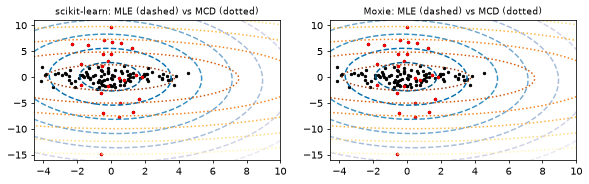

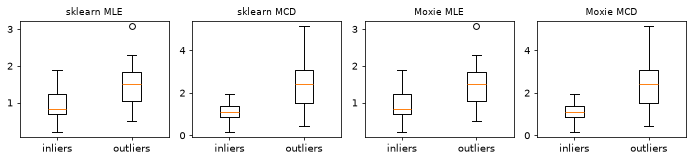

Float32 input covariance_ dtype: sklearn float64 | Moxie float32


check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
MinCovDet raw_location_,PASS,"(2,)","(2,)",5.55e-17,3.76e-16,"rtol=1e-11, atol=1e-13",,"same subsets; Float64 means/covariances of <=125 rows (summation order) and a chi2 quantile ratio (series vs SciPy, ~1e-14)"
MinCovDet raw_covariance_,PASS,"(2, 2)","(2, 2)",4.44e-16,5.38e-16,"rtol=1e-11, atol=1e-13",,"same subsets; Float64 means/covariances of <=125 rows (summation order) and a chi2 quantile ratio (series vs SciPy, ~1e-14)"
MinCovDet location_,PASS,"(2,)","(2,)",0,0,"rtol=1e-11, atol=1e-13",,"same subsets; Float64 means/covariances of <=125 rows (summation order) and a chi2 quantile ratio (series vs SciPy, ~1e-14)"
MinCovDet covariance_,PASS,"(2, 2)","(2, 2)",1.33e-15,3.7e-16,"rtol=1e-11, atol=1e-13",,"same subsets; Float64 means/covariances of <=125 rows (summation order) and a chi2 quantile ratio (series vs SciPy, ~1e-14)"
MinCovDet precision_,PASS,"(2, 2)","(2, 2)",2.22e-16,5.99e-16,"rtol=1e-11, atol=1e-13",,"same subsets; Float64 means/covariances of <=125 rows (summation order) and a chi2 quantile ratio (series vs SciPy, ~1e-14)"
MinCovDet fm_loc,PASS,"(2,)","(2,)",5.55e-17,3.76e-16,"rtol=1e-11, atol=1e-13",,"same subsets; Float64 means/covariances of <=125 rows (summation order) and a chi2 quantile ratio (series vs SciPy, ~1e-14)"
MinCovDet fm_cov,PASS,"(2, 2)","(2, 2)",4.44e-16,5.38e-16,"rtol=1e-11, atol=1e-13",,"same subsets; Float64 means/covariances of <=125 rows (summation order) and a chi2 quantile ratio (series vs SciPy, ~1e-14)"
MinCovDet corrected,PASS,"(2, 2)","(2, 2)",6.66e-16,5.63e-16,"rtol=1e-11, atol=1e-13",,"same subsets; Float64 means/covariances of <=125 rows (summation order) and a chi2 quantile ratio (series vs SciPy, ~1e-14)"
MinCovDet rw_loc,PASS,"(2,)","(2,)",0,0,"rtol=1e-11, atol=1e-13",,"same subsets; Float64 means/covariances of <=125 rows (summation order) and a chi2 quantile ratio (series vs SciPy, ~1e-14)"
MinCovDet rw_cov,PASS,"(2, 2)","(2, 2)",4.44e-16,8.14e-16,"rtol=1e-11, atol=1e-13",,"same subsets; Float64 means/covariances of <=125 rows (summation order) and a chi2 quantile ratio (series vs SciPy, ~1e-14)"


In [6]:
mx = nb.results["robust"]
fig, axes = plt.subplots(1, 2, figsize=(10, 2.6), dpi=70)
for ax, title, me, mr in ((axes[0], "scikit-learn", mahal_emp_cov, mahal_robust_cov),
                          (axes[1], "Moxie", mx["mahal_emp_cov"].reshape(xx.shape), mx["mahal_robust_cov"].reshape(xx.shape))):
    ax.scatter(X[:, 0], X[:, 1], color="black", s=6); ax.scatter(X[-n_outliers:, 0], X[-n_outliers:, 1], color="red", s=6)
    ax.contour(xx, yy, np.sqrt(me), cmap=plt.cm.PuBu_r, linestyles="dashed")
    ax.contour(xx, yy, np.sqrt(mr), cmap=plt.cm.YlOrBr_r, linestyles="dotted")
    ax.set_title(title + ": MLE (dashed) vs MCD (dotted)", fontsize=9)
plt.show()
mx_emp_mahal, mx_robust_mahal = mx["emp_mahal_raw"] ** 0.33, mx["robust_mahal_raw"] ** 0.33
fig, axes = plt.subplots(1, 4, figsize=(10, 2.4), dpi=70)
for ax, title, d in zip(axes, ("sklearn MLE", "sklearn MCD", "Moxie MLE", "Moxie MCD"),
                        (emp_mahal, robust_mahal, mx_emp_mahal, mx_robust_mahal)):
    ax.boxplot([d[:-n_outliers], d[-n_outliers:]], widths=0.25); ax.set_xticklabels(("inliers", "outliers")); ax.set_title(title, fontsize=9)
plt.tight_layout(); plt.show()
moxie_nb.side_by_side(sklearn=robust_cov.covariance_, moxie=mx["covariance_"])

# Combinatorial outputs (supports, labels) are exact. MCD estimates are Float64 means/covariances of the same
# selected subsets plus a chi2 consistency factor; the covariances are well conditioned (2x2, cond < 10), so a
# few ulps of summation-order difference remain.
EST = "same subsets; Float64 means/covariances of <=125 rows (summation order) and a chi2 quantile ratio (series vs SciPy, ~1e-14)"
for k in ("raw_location_", "raw_covariance_", "location_", "covariance_", "precision_", "fm_loc", "fm_cov",
          "corrected", "rw_loc", "rw_cov", "rw_installed", "sf_cov"):
    ref = extra[k]
    nb.compare("MinCovDet " + k, ref, mx[k], rtol=1e-11, atol=1e-13, reason=EST)
for k in ("dist_", "fm_dist", "corrected_dist"):
    nb.compare("MinCovDet " + k, extra[k], mx[k], rtol=1e-10, atol=1e-12,
               reason="squared distances through the fitted precision; direct quadratic form vs cdist**2 (documented)")
for k in ("raw_support_", "support_", "fm_sup", "rw_sup", "sf_support", "f32_support"):
    nb.compare("support mask " + k, extra[k].astype(int), mx[k], exact=True)
nb.compare("mahalanobis on the 100x100 grid (MLE)", mahal_emp_cov.ravel(), mx["mahal_emp_cov"], rtol=1e-10, atol=1e-12,
           reason="direct quadratic form vs cdist(...)**2: rounding only")
nb.compare("mahalanobis on the 100x100 grid (MCD)", mahal_robust_cov.ravel(), mx["mahal_robust_cov"], rtol=1e-10, atol=1e-12, reason="as above")
nb.compare("box-plot distances (MLE)", emp_mahal, mx_emp_mahal, rtol=1e-10, atol=1e-12, reason="as above, cube root")
nb.compare("box-plot distances (MCD)", robust_mahal, mx_robust_mahal, rtol=1e-10, atol=1e-12, reason="as above, cube root")
nb.compare("score(X) MCD / MLE, error_norm frobenius / spectral", extra["score"], mx["score"], rtol=1e-11, atol=0,
           reason="log-likelihood and norms of well-conditioned 2x2 estimates")
nb.compare("EllipticEnvelope fit_predict(X)", extra["fit_predict"], mx["fit_predict"], exact=True)
nb.compare("EllipticEnvelope predict(grid)", extra["predict_grid"], mx["predict_grid"], exact=True)
nb.compare("EllipticEnvelope decision_function(grid)", extra["decision"], mx["decision"], rtol=1e-10, atol=1e-10,
           reason="negative squared distances minus the percentile offset; rounding only")
nb.compare("EllipticEnvelope score_samples(X)", extra["score_samples"], mx["score_samples"], rtol=1e-10, atol=1e-12, reason="as above")
nb.compare("EllipticEnvelope offset_, score, weighted score", extra["env_scalars"], mx["env_scalars"], rtol=1e-11, atol=0,
           reason="offset_ is a linear-interpolated percentile of score_samples; accuracies are exact ratios")
nb.compare("Float32 MinCovDet covariance_ (values)", extra["f32_cov"], mx["f32_cov"], rtol=2e-7, atol=0,
           reason="both compute in Float64 (sklearn's np.cov path); Moxie rounds the stored array to Float32 "
                  "(<= 6e-8 relative), sklearn keeps Float64")
print("Float32 input covariance_ dtype: sklearn", extra["f32_cov"].dtype, "| Moxie", mx["f32_cov"].dtype)
nb.compare("Moxie Float32 covariance_ keeps the estimator dtype", np.array(["float32"]), np.array([str(mx["f32_cov"].dtype)]), exact=True)
nb.note("Float32 MinCovDet output dtype", "ADAPTED", "sklearn returns Float64 covariance_ for Float32 input (np.cov); Moxie "
        "keeps the static estimator dtype (documented in algorithms/robust/docs/api.md, 'Explicit Mojo differences')")
nb.note("make_pipeline(StandardScaler(), EllipticEnvelope())", "GAP", "Pipeline's final step must be a "
        "SupervisedEstimator & Predictor; unsupervised covariance estimators and outlier detectors cannot end a pipeline "
        "(compile-time rejection shown above; tracked in the covariance tracking PR, owner: pipeline)")
nb.note("MinCovDet random_state", "ADAPTED", "official example uses random_state=None (global NumPy RNG); both sides use 0. "
        "Moxie None means an entropy-seeded native state, not NumPy's global RandomState")
nb.report()
nb.assert_parity()